# 02 — Visualização, Filtros Temporais e Objetos MNE no Dataset BETA

> **Adaptação de:** `SSVEP/preprocessing.ipynb` e seção MNE de `SSVEP/beta_ml.ipynb` ([bneurd/tutoriais](https://github.com/bneurd/tutoriais)).

Neste notebook executamos exatamente as duas tarefas propostas pelo professor nos tutoriais originais:
1. Implementar e visualizar os filtros temporais Butterworth (**passa-faixa**, **passa-baixa**, **passa-alta** e **notch em 50 Hz**) nos domínios do tempo, PSD e espectrograma;
2. Criar o objeto `mne.EpochsArray` para o **Dataset BETA**, filtrá-lo e recortar as janelas temporais para comprovar visualmente:
   * **Janelas (a) `0.0 – 0.5 s` e `2.5 – 3.0 s`:** apenas ruído espontâneo (sem pico SSVEP);
   * **Janela (b) `0.5 – 2.5 s` (`0.63 – 2.5 s` sem latência):** pico SSVEP nítido cravado na frequência estimulada!

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent and not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings("ignore")

import mne
from scipy.fft import rfft, rfftfreq
from src.bneurd_beta import (
    PROCESSED_DATA_DIR,
    butter_bandpass,
    butter_highpass,
    butter_lowpass,
    butter_notch,
    create_beta_epochs,
    load_beta_subject,
)

X_s1_9ch, y_freqs_s1, y_cls_s1, blocks_s1, meta_s1 = load_beta_subject(1, channels="9ch", window="full")
sfreq = meta_s1["sfreq"]
print("Dados S1 (9 canais occipitais):", X_s1_9ch.shape, "| Canais:", meta_s1["ch_names"])

Dados S1 (9 canais occipitais): (160, 9, 750) | Canais: ['PZ', 'PO5', 'PO3', 'POZ', 'PO4', 'PO6', 'O1', 'OZ', 'O2']


### 1. Aplicação dos Filtros Butterworth (`bandpass`, `notch`) e Gráficos Tempo / PSD / Espectrograma
Adaptado diretamente da função `print_graphs` de `SSVEP/preprocessing.ipynb`, ajustando `Fs=250 Hz` e filtro *notch* para `50 Hz` (frequência da rede elétrica onde o BETA foi coletado).

Verificação numérica filtros: (160, 750) (160, 750)


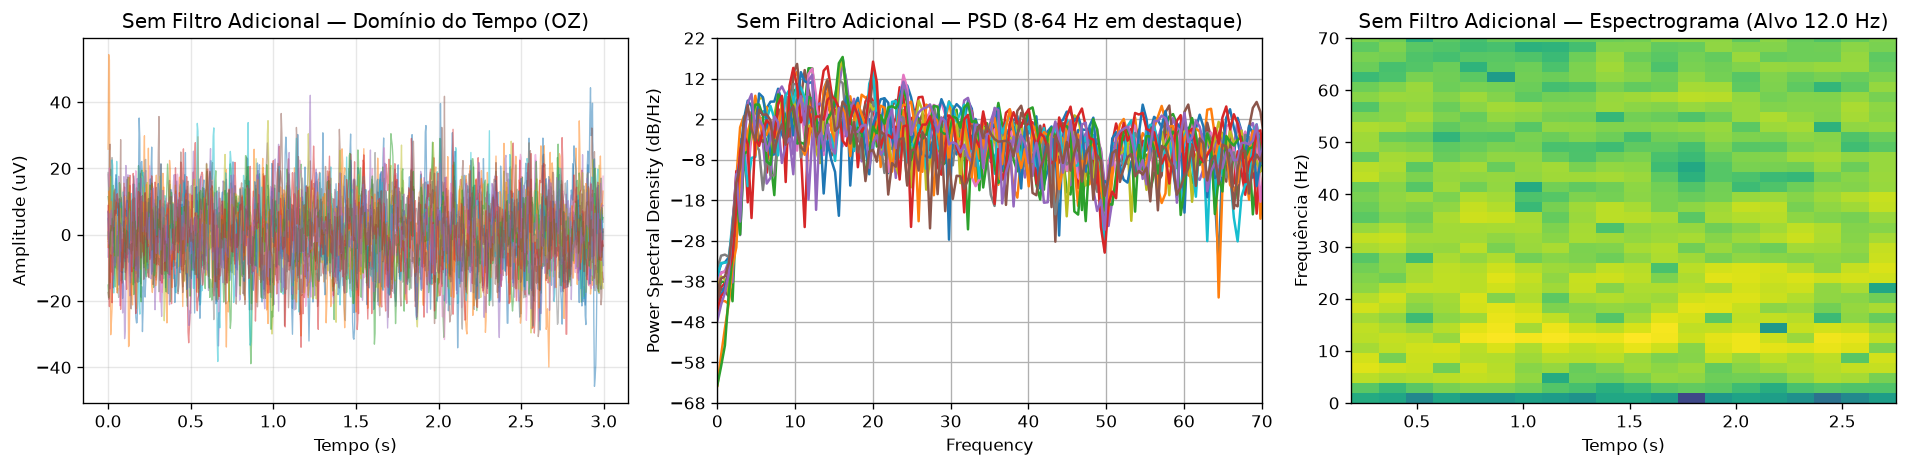

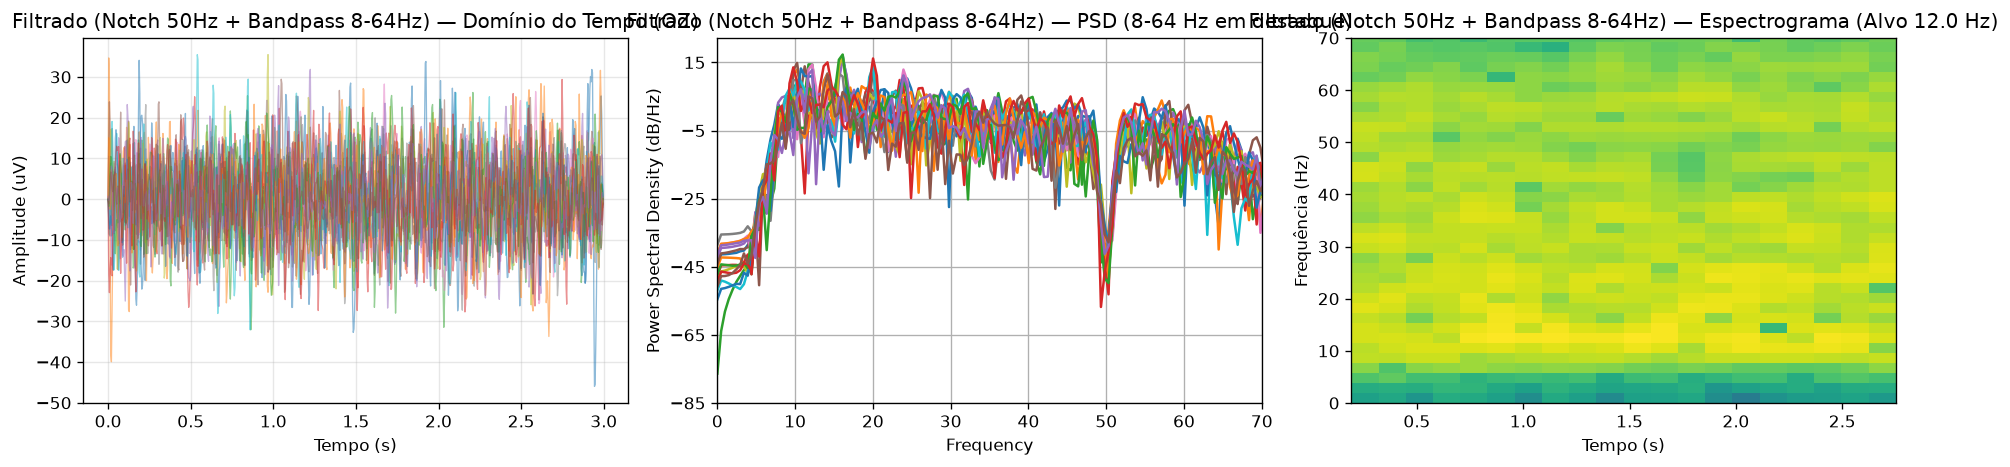

In [2]:
# Seleciona o canal OZ (índice 7 dentro dos 9 canais: PZ, PO5, PO3, POZ, PO4, PO6, O1, OZ, O2)
oz_local_idx = meta_s1["ch_names"].index("OZ")
oz_raw = X_s1_9ch[:, oz_local_idx, :]  # (160, 750)

# Aplica Notch 50 Hz + Passa-faixa 8-64 Hz (fundamental + harmônicos)
oz_notched = butter_notch(oz_raw, cutoff=50.0, var=1.5, fs=sfreq, order=4)
oz_filtered = butter_bandpass(oz_notched, lowcut=8.0, highcut=64.0, fs=sfreq, order=4)

# Também demonstra lowpass (64 Hz) e highpass (8 Hz) separadamente
oz_lp = butter_lowpass(oz_raw, highcut=64.0, fs=sfreq)
oz_hp = butter_highpass(oz_lp, lowcut=8.0, fs=sfreq)
print("Verificação numérica filtros:", oz_filtered.shape, oz_hp.shape)

def print_beta_graphs(sig_2d, title_prefix):
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    t = np.arange(sig_2d.shape[-1]) / sfreq
    for i in range(0, 160, 10):
        axes[0].plot(t, sig_2d[i, :], alpha=0.5, linewidth=0.8)
    axes[0].set_title(f"{title_prefix} — Domínio do Tempo (OZ)")
    axes[0].set_xlabel("Tempo (s)")
    axes[0].set_ylabel("Amplitude (uV)")
    axes[0].grid(alpha=0.3)

    for i in range(0, 160, 10):
        axes[1].psd(sig_2d[i, 157:625], NFFT=512, Fs=sfreq)
    axes[1].set_xlim(0, 70)
    axes[1].set_title(f"{title_prefix} — PSD (8-64 Hz em destaque)")

    axes[2].specgram(sig_2d[20, :], NFFT=128, Fs=sfreq, noverlap=96, cmap="viridis")
    axes[2].set_ylim(0, 70)
    axes[2].set_title(f"{title_prefix} — Espectrograma (Alvo {y_freqs_s1[20]:.1f} Hz)")
    axes[2].set_xlabel("Tempo (s)")
    axes[2].set_ylabel("Frequência (Hz)")

    plt.tight_layout()
    plt.show()

print_beta_graphs(oz_raw, "Sem Filtro Adicional")
print_beta_graphs(oz_filtered, "Filtrado (Notch 50Hz + Bandpass 8-64Hz)")

### 2. Criação do Objeto `mne.EpochsArray` e Análise das Janelas com vs. sem Estímulo
Seguindo o roteiro exato de `SSVEP/beta_ml.ipynb`:
1. Criar o objeto `MNE` a partir dos dados do participante;
2. Aplicar no objeto `MNE` o filtro passa-faixa (`6 – 18 Hz` para isolar as fundamentais de `8.0 – 15.8 Hz`, e salvando também a versão `8 – 64 Hz` em `.fif`);
3. Criar cópias do objeto `MNE` com fatias menores:
   * **(a)** `0.0 – 0.5 s` (pré-estímulo) e `2.5 – 3.0 s` (pós-estímulo): apenas ruído;
   * **(b)** `0.5 – 2.5 s` (estímulo SSVEP);
4. Aplicar `scipy.fft` e plotar no domínio da frequência comprovando a presença do pico SSVEP apenas na janela estimulada!

<EpochsArray | 160 events (all good), 0 – 2.996 s (baseline off), ~8.3 MiB, data loaded,
 '8.0': 4
 '8.2': 4
 '8.4': 4
 '8.6': 4
 '8.8': 4
 '9.0': 4
 '9.2': 4
 '9.4': 4
 '9.6': 4
 '9.8': 4
 and 30 more events ...>


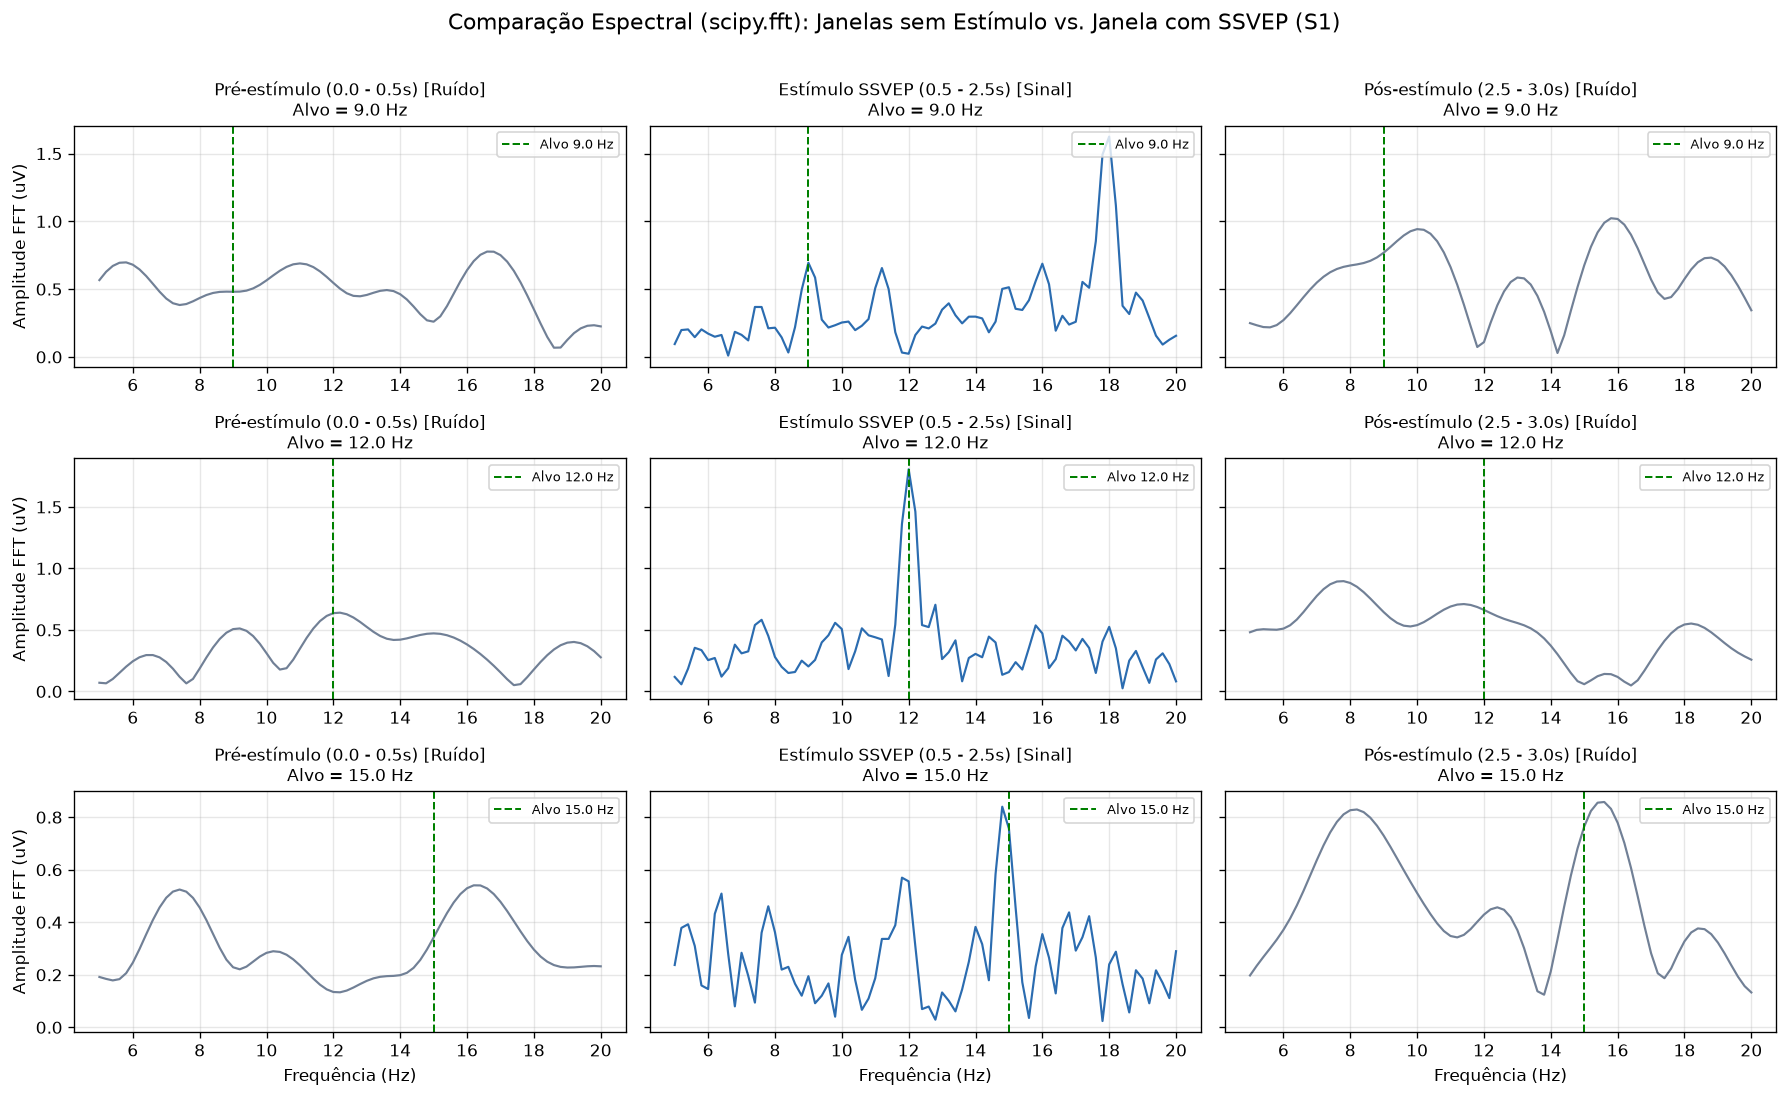

In [3]:
mne_epochs = create_beta_epochs(X_s1_9ch, y_freqs_s1, ch_names=meta_s1["ch_names"], sfreq=sfreq, tmin=0.0)
print(mne_epochs)

# Versão filtrada 6-18 Hz (conforme roteiro beta_ml.ipynb para visualização da fundamental)
mne_6_18 = mne_epochs.copy().filter(l_freq=6.0, h_freq=18.0, verbose=False)

# Cópias fatiadas nos 3 momentos do ensaio
epo_pre_noise = mne_6_18.copy().crop(tmin=0.0, tmax=0.496)
epo_stim = mne_6_18.copy().crop(tmin=0.5, tmax=2.496)
epo_post_noise = mne_6_18.copy().crop(tmin=2.5, tmax=2.996)

# Compara via scipy.fft para 3 frequências alvo exemplares: 9.0 Hz, 12.0 Hz e 15.0 Hz
demo_targets = ["9.0", "12.0", "15.0"]
fig, axes = plt.subplots(len(demo_targets), 3, figsize=(15, 9), sharey="row")

for row_idx, f_str in enumerate(demo_targets):
    f_val = float(f_str)
    windows = [
        ("Pré-estímulo (0.0 - 0.5s) [Ruído]", epo_pre_noise[f_str]),
        ("Estímulo SSVEP (0.5 - 2.5s) [Sinal]", epo_stim[f_str]),
        ("Pós-estímulo (2.5 - 3.0s) [Ruído]", epo_post_noise[f_str]),
    ]
    for col_idx, (w_title, ep_slice) in enumerate(windows):
        # Média sobre os 4 blocos e os 9 canais occipitais (convertendo de V para uV)
        sig_mean = ep_slice.get_data(copy=False).mean(axis=(0, 1)) * 1e6
        n_fft = 1250
        amps = np.abs(rfft(sig_mean, n=n_fft)) / len(sig_mean)
        freqs = rfftfreq(n_fft, d=1.0 / sfreq)
        mask = (freqs >= 5.0) & (freqs <= 20.0)

        ax = axes[row_idx, col_idx]
        ax.plot(freqs[mask], amps[mask], color="#2b6cb0" if col_idx == 1 else "#718096", linewidth=1.3)
        ax.axvline(f_val, color="green", linestyle="--", linewidth=1.2, label=f"Alvo {f_val} Hz")
        ax.set_title(f"{w_title}\nAlvo = {f_val} Hz", fontsize=10)
        ax.grid(alpha=0.3)
        if col_idx == 0:
            ax.set_ylabel("Amplitude FFT (uV)")
        if row_idx == len(demo_targets) - 1:
            ax.set_xlabel("Frequência (Hz)")
        ax.legend(loc="upper right", fontsize=8)

plt.suptitle("Comparação Espectral (scipy.fft): Janelas sem Estímulo vs. Janela com SSVEP (S1)", fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

### 3. Visualização `compute_psd(method='multitaper')` e Salvamento em `.fif`
Como em `SSVEP/preprocessing.ipynb`, verificamos também o método nativo `compute_psd(method='multitaper')` do MNE na banda completa `8–64 Hz` (que preserva os harmônicos $2f$ e $3f$) e salvamos o arquivo `.fif` filtrado em `data/processed/beta_s1_filtered-epo.fif` para o próximo notebook!

Arquivo MNE salvo com sucesso em: C:\Users\victor\Documents\GitHub\OPT098\data\processed\beta_s1_filtered-epo.fif


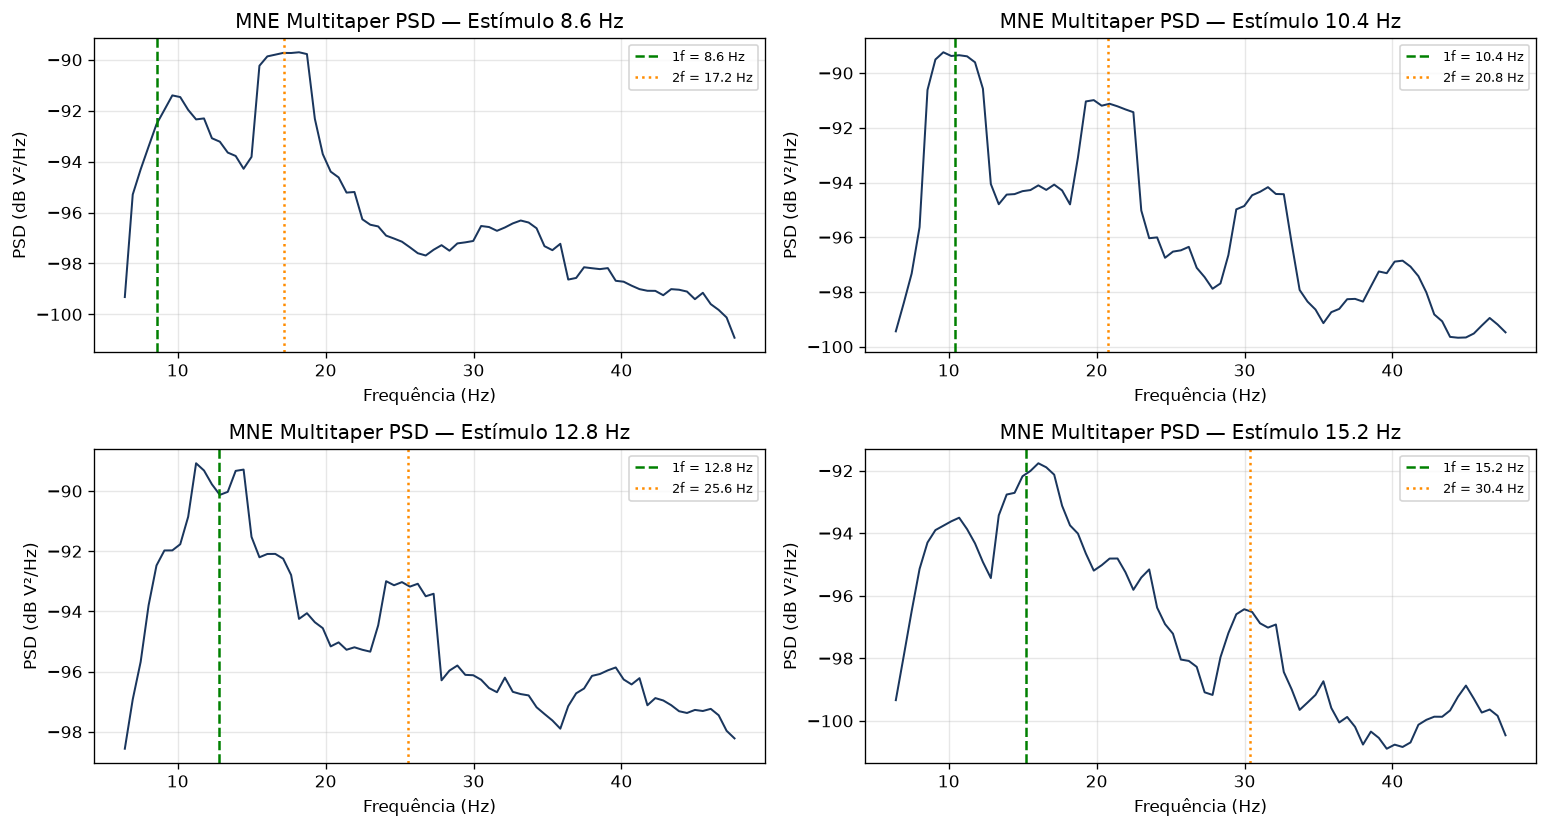

In [4]:
mne_filtered_wide = mne_epochs.copy().filter(l_freq=8.0, h_freq=64.0, verbose=False)
mne_stim_clean = mne_filtered_wide.copy().crop(tmin=0.63, tmax=2.496)

PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)
fif_path = PROCESSED_DATA_DIR / "beta_s1_filtered-epo.fif"
mne_stim_clean.save(fif_path, overwrite=True, verbose=False)
print("Arquivo MNE salvo com sucesso em:", fif_path)

# Plota PSD multitaper para 4 alvos demonstrando fundamental + 2º harmônico
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for ax, f_str in zip(axes.flatten(), ["8.6", "10.4", "12.8", "15.2"]):
    f0 = float(f_str)
    psd_spec = mne_stim_clean[f_str].compute_psd(method="multitaper", fmin=6.0, fmax=48.0, verbose=False)
    psds, f_axis = psd_spec.get_data(return_freqs=True)
    psd_db = 10 * np.log10(psds.mean(axis=(0, 1)) + 1e-20)
    ax.plot(f_axis, psd_db, color="#1a365d", linewidth=1.2)
    ax.axvline(f0, color="green", linestyle="--", label=f"1f = {f0:.1f} Hz")
    ax.axvline(2 * f0, color="darkorange", linestyle=":", label=f"2f = {2*f0:.1f} Hz")
    ax.set_title(f"MNE Multitaper PSD — Estímulo {f_str} Hz")
    ax.set_xlabel("Frequência (Hz)")
    ax.set_ylabel("PSD (dB V²/Hz)")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()